# **Домашнее задание №1 (pro)**

В этом домашнем задании вам будет необходимо:
*  обучить модель регрессии для предсказания стоимости автомобилей;


**Оценивание**

Максимальная оценка за ДЗ — **10 баллов**:
- Части 1–5 (EDA, модели, категориальные признаки, Feature Engineering, бизнес-метрика) — 5 баллов;
- Часть 6, оформление репозитория — 2 балла;
- Часть 7, Streamlit-приложение — 3 балла.

**Дедлайн: 2 декабря**

**Примечание**

В каждой части оцениваются как код, **так и ответы на вопросы.**

Если нет одного и/или другого, то часть баллов за соответствующее задание снимается.

In [319]:
!pip install -q ydata-profiling "numpy<=2.3"  # numba в Colab пока не поддерживает NumPy 2.4
!pip install fg-data-profiling #в документации нашел
!pip install phik

In [373]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import seaborn as sns
import data_profiling
from data_profiling import ProfileReport
import re
import phik
import pickle
import sklearn

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.metrics import r2_score, mean_squared_error as MSE
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # для OHE можно использовать и pd.get_dummies

random.seed(42)
np.random.seed(42)

### **Задание 0**
Давайте зафиксируем важный момент.

**Задание 0 (0 баллов).**
Изучите и ответьте на вопрос: для чего фиксируем сиды в домашках?

Сиды фиксируются для того чтобы зафиксировать случайность, что позволит получить на другом компьютере такие же результаты как и у меня

# **Часть 1 | EDA**


Первая часть состоит из классических шагов EDA:

- Базовый EDA и обработка признаков (1.4 балла)
- Визуализации признаков и их анализ (0.9 балла)

Всего за эту часть можно набрать 2.3 балла.

## **Простейший EDA и обработка признаков (1.4 балла)**

In [321]:
df_train = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_train.csv')
df_test = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv')

print("Train data shape:", df_train.shape)
print("Test data shape: ", df_test.shape)

Train data shape: (6999, 13)
Test data shape:  (1000, 13)


### **Задание 1 (0.4 балла)**
Выполните операции, направленные на базовое исследование данных:

- [ ] Посмотрите, есть ли в датасете пропуски. Запишите/выведите названия колонок, для которых есть пропущенные значения (0.1 балла)
- [ ] Посмотрите, есть ли в данных явные дубликаты (0.05 балла)
- [ ] Постройте дашборд в одну строку, используя [ydata-profiling](https://github.com/ydataai/ydata-profiling) (0.1 балла)
- [ ] Опишите базовые выводы (какие — выберите сами), используя дашборд (0.15 балла).

**Ваш ответ здесь.**

In [322]:
#пропуски в данных
df_mis = df_train.isna().sum()
missing_features = df_mis[df_mis > 0].index
missing_features

Index(['mileage', 'engine', 'max_power', 'torque', 'seats'], dtype='object')

In [323]:
df_mis_test = df_test.isna().sum()
df_mis_test[df_mis_test > 0].index

Index(['mileage', 'engine', 'max_power', 'torque', 'seats'], dtype='object')

In [324]:
#дубликаты
df_train[df_train.duplicated()].sort_index()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
254,Hyundai Grand i10 Sportz,2017,450000,35000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197 CC,82 bhp,114Nm@ 4000rpm,5.0
258,Maruti Swift VXI,2012,330000,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,85.8 bhp,114Nm@ 4000rpm,5.0
324,Jaguar XE 2016-2019 2.0L Diesel Prestige,2017,2625000,9000,Diesel,Dealer,Automatic,First Owner,13.6 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
325,Lexus ES 300h,2019,5150000,20000,Petrol,Dealer,Automatic,First Owner,22.37 kmpl,2487 CC,214.56 bhp,202Nm@ 3600-5200rpm,5.0
326,Jaguar XF 2.0 Diesel Portfolio,2017,3200000,45000,Diesel,Dealer,Automatic,First Owner,19.33 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6880,Renault Captur 1.5 Diesel RXT,2018,1265000,12000,Diesel,Individual,Manual,First Owner,20.37 kmpl,1461 CC,108.45 bhp,240Nm@ 1750rpm,5.0
6881,Maruti Ciaz Alpha Diesel,2019,1025000,32000,Diesel,Individual,Manual,First Owner,28.09 kmpl,1248 CC,88.50 bhp,200Nm@ 1750rpm,5.0
6989,Maruti Swift Dzire VDI,2015,625000,50000,Diesel,Individual,Manual,First Owner,26.59 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
6997,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


In [325]:
profile = ProfileReport(df_train, title="Profiling Report")
profile

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 13/13 [00:01<00:00, 10.84it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Я выделю наиболее важные:
- Всего в датасете 13 признаков; наблюдений 6999; 1005 пропущенных значений, с которыми необходимо будет разобраться; 493 дублирующихся строк
- Числовые признаки скошены вправо и влево, возможно необходимо будет отнормировать
- Также можно сказать о том, что в каждом отдельно взятом категориальном признаков у нас дисбаланс классов.
- km_driven, selling_price, year сильно связаны друг с другом, это видно по корреляционной матрице

### **Задание 2 (0.2 балла)**
Проанализируйте статистики датасета.

**Ваша задача:**
- [ ] Посчитайте основные статистики по числовым столбцам для трейна и теста
- [ ] Посчитайте основные статистики по категориальным столбцам для трейна и теста
- [ ] Сравните среднее и медиану внутри `train`, внутри `test` и между собой. О чём могут говорить результаты?
- [ ] Сделайте выводы по статистикам. Отсутствие выводов равносильно по баллам невыполнению задания.

**Подсказка:**

Используйте ``.describe()`` с нужным(и) аргументом(-ами).

In [326]:
# задание 1-2 — статистики
print('Статистики по числовым признакам')
display(df_train.describe(include=['int', 'float']))
display(df_test.describe(include=['int', 'float']))
print('\n')
print('Статистики по категориальным признакам')
display(df_train.describe(include='object'))
display(df_test.describe(include='object'))


Статистики по числовым признакам


,year,selling_price,km_driven,seats
count,6999.000000,6.999000e+03,6.999000e+03,6797.000000
mean,2013.818403,6.395152e+05,6.958462e+04,5.419008
std,4.053095,8.089419e+05,5.772400e+04,0.965767
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.700000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


,year,selling_price,km_driven,seats
count,1000.000000,1.000000e+03,1000.000000,981.000000
mean,2013.681000,6.179010e+05,71393.341000,5.410805
std,4.012149,7.585539e+05,48486.218662,0.919985
min,1995.000000,3.100000e+04,1303.000000,4.000000
25%,2011.000000,2.500000e+05,37000.000000,5.000000
50%,2014.000000,4.349990e+05,61500.000000,5.000000
75%,2017.000000,6.700000e+05,100000.000000,5.000000
max,2020.000000,6.000000e+06,375000.000000,9.000000




Статистики по категориальным признакам


,name,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque
count,6999,6999,6999,6999,6999,6797,6797,6803,6796
unique,1924,4,3,2,5,386,120,316,419
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner,18.9 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm
freq,116,3793,5826,6095,4587,197,885,330,468


,name,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque
count,1000,1000,1000,1000,1000,981,981,981,981
unique,621,4,3,2,5,237,88,182,226
top,Maruti Alto 800 LXI,Diesel,Individual,Manual,First Owner,18.6 kmpl,1248 CC,74 bhp,200Nm@ 1750rpm
freq,15,534,837,877,623,23,116,43,57


#### Сравните среднее и медиану внутри train, внутри test и между собой. О чём могут говорить результаты?

- Можно заметить, что медиана что в `train`, что в `test` меньше чем среднее, что указывает на наличие **правосторонней ассиметрии в данных**: дорогие автомобили и автомобили с большим пробегом увеличивают среднее
- Также как я писал ранее, необходимо будет отмасштабировать и преобразовать числовые признаки из-за большого масштаба. Также некоторые признаки, описывающие числовые значения, попали в категориальные признаки, их также надо будет преобразовать.
- В `train` и `test` мы имеем примерно одинаковые значения. В признаке `selling_price` в тренировочной среднее чуть больше чем в тесте, а в `km_driven` наоборот у теста значение среднего больше. `Медиана` ведет себя таким же образом.


### **Задание 3 (0.2 балла)**

- [ ] Посмотрите, есть ли в трейне объекты с одинаковым признаковым описанием (целевую переменную следует исключить). Если есть, то сколько? (0.01 балла)
- [ ] Отобразите такие объекты (0.01 балла)
- [ ] Удалите повторяющиеся строки. Если при одинаковом признаковом описании цены на автомобили отличаются, то оставьте первую строку по этому автомобилю (0.01 балла)
- [ ]  Обновите индексы строк таким образом, чтобы они шли от 0 без пропусков (0.01 балла)
- [ ] Подумайте, могут ли в данных быть другие скрытые дубли? Предложите, как их можно отлавливать. (0.16 балла)

P.S. Тут данные без подвоха, но выводы нам нужны.

In [327]:
print(f'Всего дубликатов: {df_train.drop(columns="selling_price").duplicated().sum().item()}')
display(df_train[df_train.drop(columns="selling_price").duplicated()])

Всего дубликатов: 1159


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
254,Hyundai Grand i10 Sportz,2017,450000,35000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197 CC,82 bhp,114Nm@ 4000rpm,5.0
258,Maruti Swift VXI,2012,330000,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,85.8 bhp,114Nm@ 4000rpm,5.0
268,Maruti Swift Dzire VXI,2014,400000,70000,Petrol,Individual,Manual,Second Owner,19.1 kmpl,1197 CC,85.8 bhp,114Nm@ 4000rpm,5.0
324,Jaguar XE 2016-2019 2.0L Diesel Prestige,2017,2625000,9000,Diesel,Dealer,Automatic,First Owner,13.6 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
325,Lexus ES 300h,2019,5150000,20000,Petrol,Dealer,Automatic,First Owner,22.37 kmpl,2487 CC,214.56 bhp,202Nm@ 3600-5200rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6947,Chevrolet Spark 1.0 LS,2010,140000,60000,Petrol,Individual,Manual,Second Owner,18.0 kmpl,995 CC,62 bhp,90.3Nm@ 4200rpm,5.0
6984,Ford Freestyle Titanium Plus Diesel BSIV,2018,746000,24000,Diesel,Individual,Manual,First Owner,24.4 kmpl,1498 CC,98.63 bhp,215Nm@ 1750-3000rpm,5.0
6989,Maruti Swift Dzire VDI,2015,625000,50000,Diesel,Individual,Manual,First Owner,26.59 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
6997,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


In [328]:
df_train = df_train.drop_duplicates(subset = df_train.drop(columns='selling_price'), keep='first')
df_train.reset_index(drop=True, inplace=True)
df_train

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
3,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0
4,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000,Petrol,Individual,Manual,First Owner,20.14 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5835,Hyundai Santro Xing GLS,2008,120000,191000,Petrol,Individual,Manual,First Owner,17.92 kmpl,1086 CC,62.1 bhp,96.1Nm@ 3000rpm,5.0
5836,Maruti Wagon R VXI BS IV with ABS,2013,260000,50000,Petrol,Individual,Manual,Second Owner,18.9 kmpl,998 CC,67.1 bhp,90Nm@ 3500rpm,5.0
5837,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
5838,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0


In [329]:
assert df_train.shape == (5840, 13)

- Один и тот же автомабиль может быть записан по-разному: в одной строке с большой буквы в другой с маленькой, где-то проблем лишний поставили. Для поиска можно привести текст к единому регистру, убрать лишние пробелы и сравнить похожие названия.
- Числовые значения могут быть также по-разному записаны. Например, `1248 CC` и `1248CC`, `74 bhp` и `74.0 bhp`.
- В одной записи признак заполнен, а в другой нет. Такие пары можно искать по совпадающим полям, если совпадение больше, чем в `каком-то проценте` характеристик.
- Машина могло быть зарегистирована несколько раз, при этом с чуть-чуть разным пробегом.

### **Задание 4 (0.25 балла)**

Вы могли заметить, что с признаками ``mileage, engine, max_power и torque`` всё не очень хорошо. Они распознаются как строки (можно убедиться в этом, вызвав `data.dtypes`). Однако эти переменные не являются категориальными — они — числа. Соответственно, нужно привести их к числовому виду.

**Задача:**
* [ ] Уберите единицы измерения для признаков ``mileage, engine, max_power``.
* [ ] Приведите тип данных к ``float``.
* [ ] Предобработайте признак `torque` — разделите его на два: собственно `torque` и `max_torque_rpm`. Учтите единицы измерения


**Важно**
- Все действия нужно производить над обоими датасетами — `train` и `test`.

In [330]:
def process_missing_features(row):
    for col in ["mileage", "engine", "max_power"]:
        pattern = re.search(r"\d+(?:\.\d+)?", str(row[col]))
        row[col] = float(pattern.group()) if pattern else np.nan

    text = str(row["torque"]).lower().replace(",", "")
    numbers = re.findall(r"\d+(?:\.\d+)?", text)

    torque = float(numbers[0]) if numbers else np.nan

    if "kgm" in text:
        torque *= 9.80665

    row["torque"] = torque

    row["max_torque_rpm"] = (max(float(number) for number in numbers[1:]) if len(numbers) > 1 else np.nan)

    return row


df_train = df_train.apply(process_missing_features, axis=1)
df_test = df_test.apply(process_missing_features, axis=1)

df_train[missing_features] = df_train[missing_features].astype(float)
df_test[missing_features] = df_test[missing_features].astype(float)

In [331]:
df_train[np.append(missing_features, 'max_torque_rpm')]

,mileage,engine,max_power,torque,seats,max_torque_rpm
0,23.40,1248.0,74.00,190.000000,5.0,2000.0
1,21.14,1498.0,103.52,250.000000,5.0,2500.0
2,23.00,1396.0,90.00,219.668960,5.0,2750.0
3,16.10,1298.0,88.20,112.776475,5.0,4500.0
4,20.14,1197.0,81.86,113.750000,5.0,4000.0
...,...,...,...,...,...,...
5835,17.92,1086.0,62.10,96.100000,5.0,3000.0
5836,18.90,998.0,67.10,90.000000,5.0,3500.0
5837,18.50,1197.0,82.85,113.700000,5.0,4000.0
5838,16.80,1493.0,110.00,235.359600,5.0,2750.0


### **Задание 5 (0.15 балла)**

На первом шаге мы обнаружили пропуски. Давайте избавимся от них.

**Задание:**
- [ ] Заполните пропуски в столбцах медианами. Убедитесь, что после заполнения пропусков не осталось.
- [ ] Почему стоит применять именно медиану? Могли ли мы применить среднее? Обоснуйте свое рассуждение.
- [ ] Как правильно считать медиану для заполнения? Выберите верное утверждение:
 - По тестовым свою, по тренировочным — свою
 - По тренировочным данным для `train` и `test`

In [332]:
print(f'Пропуски в df_train до заполнения: {df_train.isna().sum().sum()}')
print(f'Пропуски в df_test до заполнения: {df_test.isna().sum().sum()}')

df_train.fillna(df_train.select_dtypes(include=['int','float']).median(), inplace=True)
df_test.fillna(df_train.select_dtypes(include=['int','float']).median(), inplace=True)

print(f'Пропуски в df_train после заполнения: {df_train.isna().sum().sum()}')
print(f'Пропуски в df_test после заполнения: {df_test.isna().sum().sum()}')

Пропуски в df_train до заполнения: 1119
Пропуски в df_test до заполнения: 118
Пропуски в df_train после заполнения: 0
Пропуски в df_test после заполнения: 0


1. Стоит применять именно медиану, так как у нас скошенные данные и есть выбросы, а медиана как раз более устойчива к ним в отличии от среднего. Большие значения будут сильно увеличивать среднее, а нам это не нужно.
2. По тренировочным данным для train и test, так как тестовая выборка не должна ничего знать про тренировочную. Иначе мы получим Data Leakage.


### **Задание 6 (0.1 балла)**

Теперь, когда не осталось пропусков, давайте преобразуем столбцы к более подходящим типам. А именно столбцы ``engine`` и ``seats`` приведём к `int`.

- [ ] Осуществите приведение столбцов к необходимому типу.
- [ ] Ответьте на вопрос — почему ``seats`` (хоть мы этого и не делаем) можно рассматривать как категориальную переменную?

In [333]:
display(df_train.dtypes)
df_train['engine'] = df_train['engine'].astype(int)
df_train['seats'] = df_train['seats'].astype(int)

df_test['engine'] = df_test['engine'].astype(int)
df_test['seats'] = df_test['seats'].astype(int)
display(df_train.dtypes)

,0
name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object
mileage,float64
engine,float64


,0
name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object
mileage,float64
engine,int64


`seats` можно рассматривать как категориальную перемнную, так как признак принимает ограниченное количество значений заранее известных, что позволяет нам рассматривать отдельно каждое значение как категорию. Например, машина с 2 сидениями, 3 сидениями и так далее.

### **Задание 7 (0.1 балла)**

Снова вызовите метод describe и проанализируйте статистики.

**Ответьте на вопрос:**
- [ ] Есть ли основания предполагать, что заполнение пропусков сдвинуло наши распределения? Могло ли это вообще возникнуть?

In [334]:
display(df_train.describe())
display(df_test.describe())

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
count,5840.000000,5.840000e+03,5.840000e+03,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000
mean,2013.428425,5.229601e+05,7.395224e+04,19.430841,1429.448973,87.906371,175.930478,5.426712,3045.789041
std,4.095622,5.354320e+05,6.007114e+04,3.985973,485.662834,31.640418,116.757608,0.982344,911.039323
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,0.000000,47.071920,2.000000,1400.000000
25%,2011.000000,2.500000e+05,3.900000e+04,16.950000,1197.000000,68.000000,111.800000,5.000000,2250.000000
50%,2014.000000,4.050000e+05,7.000000e+04,19.370000,1248.000000,81.860000,160.000000,5.000000,3000.000000
75%,2017.000000,6.400000e+05,1.000000e+05,22.300000,1498.000000,99.000000,200.055660,5.000000,4000.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,3726.527000,14.000000,21800.000000


,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
count,1000.000000,1.000000e+03,1000.000000,1000.00000,1000.00000,1000.000000,1000.000000,1000.000000,1000.00000
mean,2013.681000,6.179010e+05,71393.341000,19.33881,1454.87600,90.841670,177.617377,5.403000,3098.27600
std,4.012149,7.585539e+05,48486.218662,3.95175,521.99574,34.893389,103.734516,0.912921,877.14712
min,1995.000000,3.100000e+04,1303.000000,0.00000,624.00000,34.200000,48.000000,4.000000,1500.00000
25%,2011.000000,2.500000e+05,37000.000000,16.55000,1197.00000,69.000000,111.700000,5.000000,2500.00000
50%,2014.000000,4.349990e+05,61500.000000,19.37000,1248.00000,82.425000,160.000000,5.000000,3000.00000
75%,2017.000000,6.700000e+05,100000.000000,22.30000,1582.00000,102.000000,205.000000,5.000000,4000.00000
max,2020.000000,6.000000e+06,375000.000000,32.26000,3604.00000,280.000000,1421.964250,9.000000,5200.00000


В `train` средняя цена снизилась с **639 515 до 522 960 - на 18,2%**. Также уменьшилось количество строк, поэтому изменение средней цены связано с изменением выборки в большей степени, нежели с заполнением пропусков.

В `test` для `seats` после заполнения среднее изменилось с **5,4108 до 5,4030**, стандартное отклонение — с **0,9200 до 0,9129**. Здесь изменение небольшое. Сложно определить только по таблицам сдвинулось распределение или нет.

## **Визуализации и корреляция (0.9 балла)**

Визуализация данных — важный шаг в работе. Визуализировать данные необходимо, например, чтобы:

- Оценить распределения признаков самих по себе (это может натолкнуть вас на мысли о модели, которую можно использовать)
- Сравнить распределения на `train` и `test` — чтобы проверить, насколько информация, на которой вы будете обучаться согласуется с той, на которой модель должна работать
- Оценить есть ли явная связь признаков с целевой переменной

**Важно:**

Если распределения на `train` и `test` не совпадают, это не значит, что нужно перемешивать данные! Более корректно актуализировать задачу и уточнить, а не устарели ли данные `train`.

**Если вы будете подгонять распределения, то можете встретиться с переобучением!**

### **Задание 8 (0.25 балла)**

Шаг 1.
- [ ] Воспользуйтесь `pairplot` из библиотеки `seaborn`, чтобы визуализировать попарные распределения числовых признаков для `train`
- [ ] По полученному графику ответьте на вопросы:
 - Можно ли предположить на основе распределений связь признаков с целевой переменной?
 - Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?

Шаг 2.

- [ ] Постройте pairplot по тестовым данным
- [ ] Ответьте на вопрос "Похожими ли оказались совокупности при разделении на трейн и тест?"

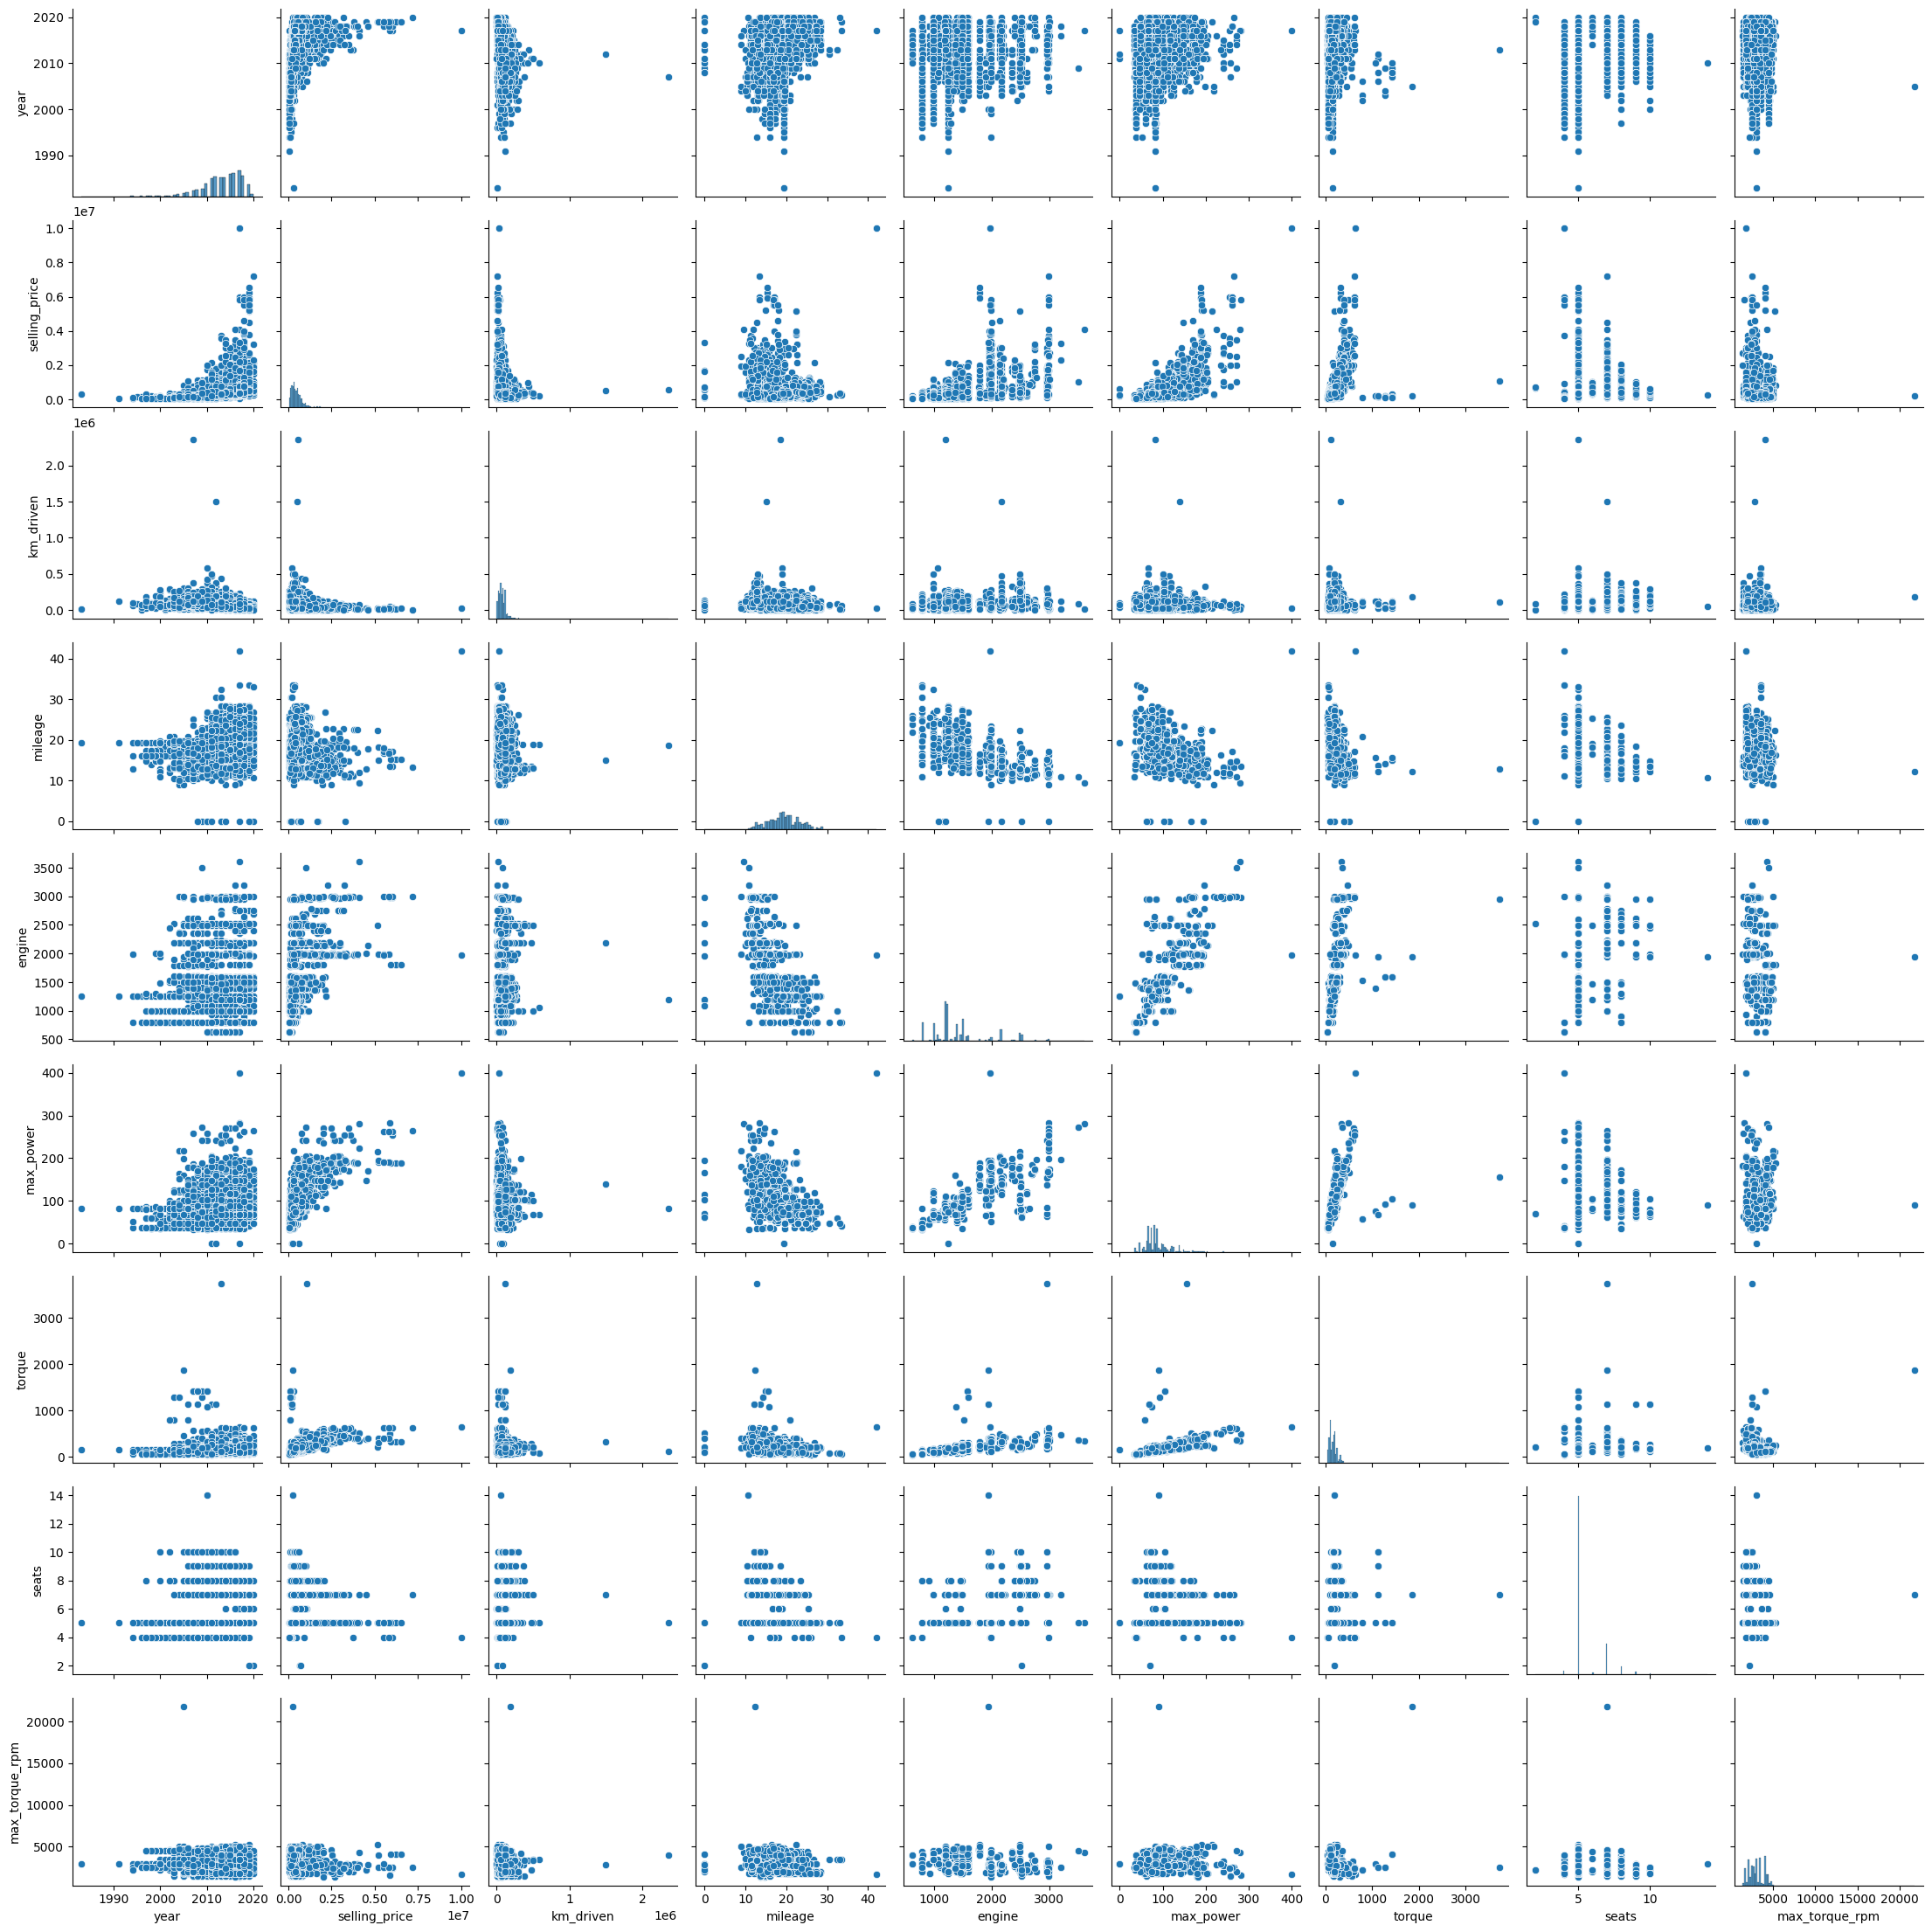

In [335]:
sns.pairplot(df_train.select_dtypes(['int', 'float']))

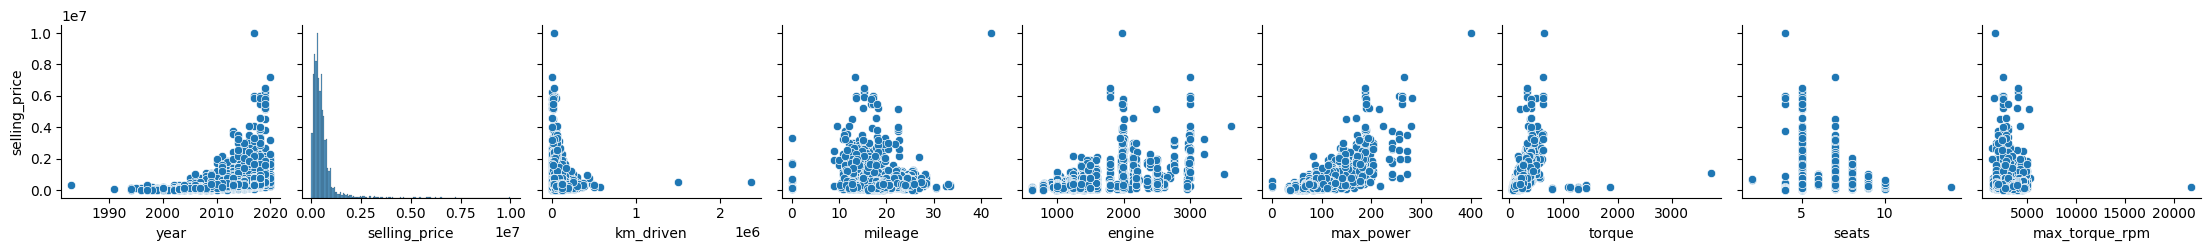

In [336]:
sns.pairplot(data=df_train, y_vars=["selling_price"])
plt.show()

- `year`, `engine`, `max_power` связаны с целевой переменной положительно. Более мощные автомобили с большим объемом двигателя и выпущенные недавно стоят дороже.
- `km_driven` связан отрицательно с целевой перемнной, большой пробег ведет к падению стоимости автомобиля.
- Для остальных признаков какой-то очевидной сильной связи не наблюдается.
- Можно выдвинуть гипотезу по поводу корреляций признаков, однако можно предположить какая она положительная или отрицательная, но силу этой корреляции оценить точно нельзя.

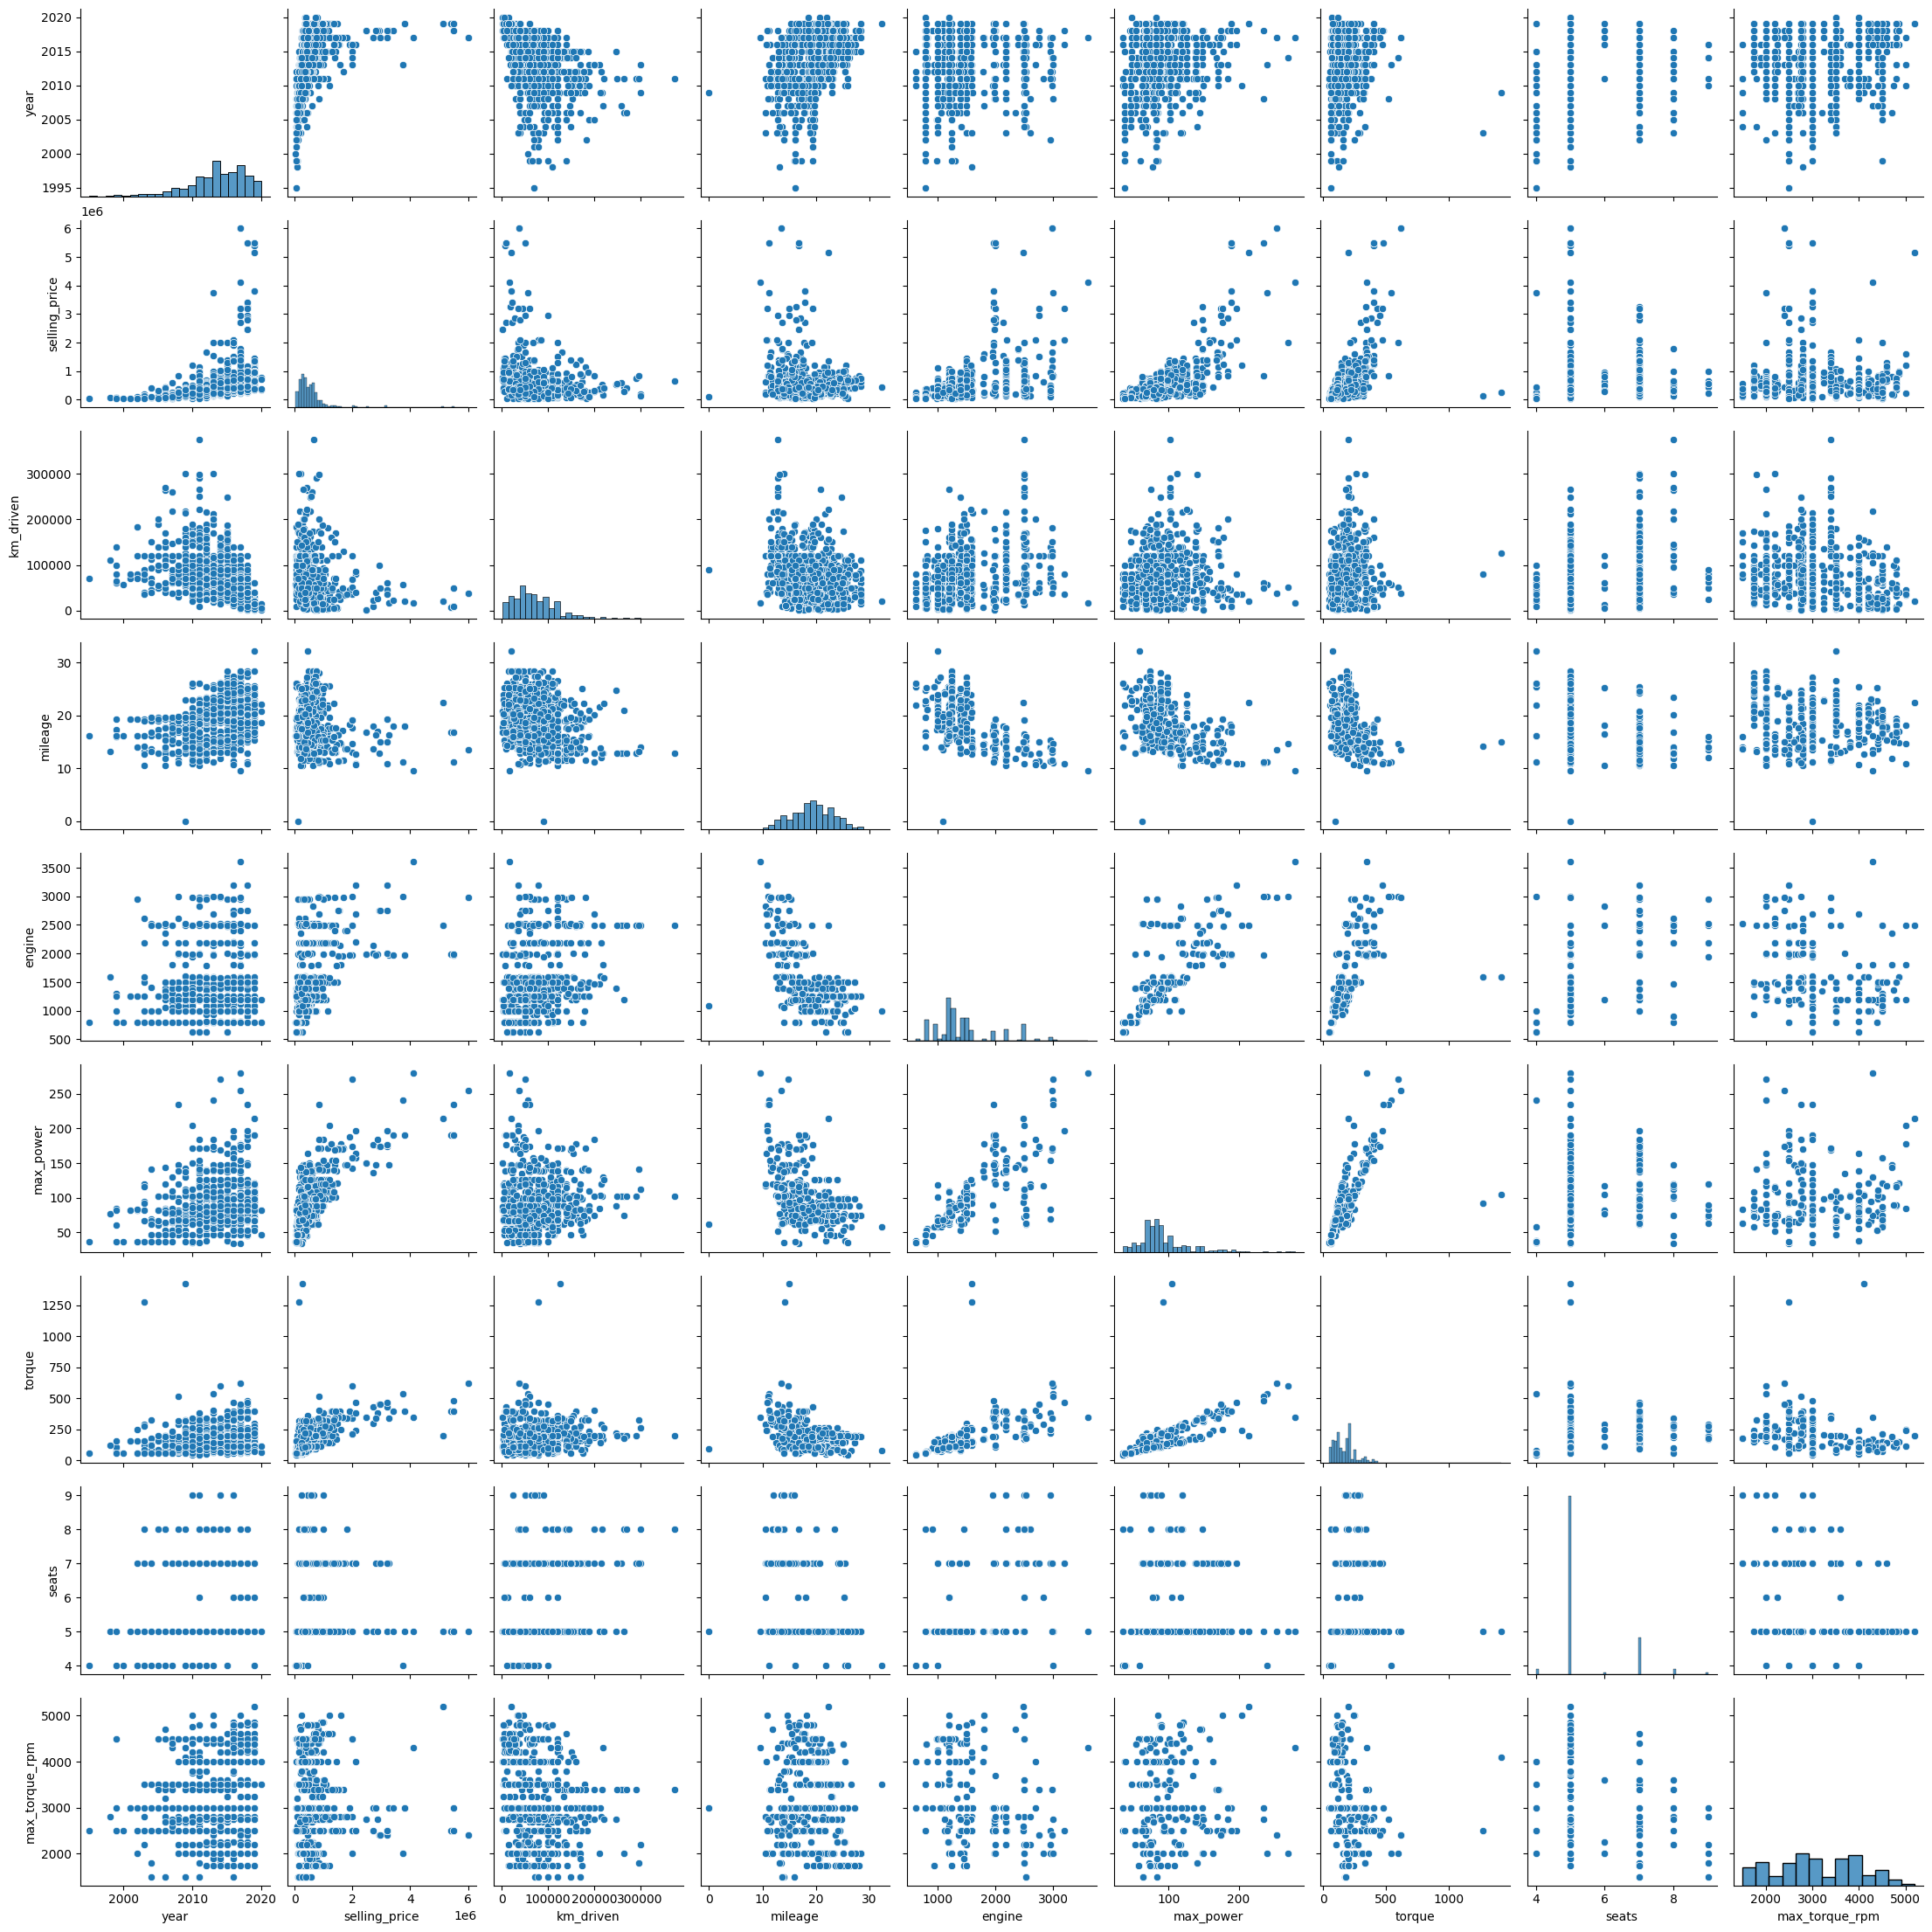

In [337]:
sns.pairplot(df_test.select_dtypes(['int', 'float']))

- Основные формы распределения сохраняются и зависимости между признаками, это видно по графикам. В обеих выборках цена и пробег имеют длинный правый хвост, преобладают пятиместные автомобили. Цена положительно связана с мощностью и годом выпуска, а мощность - с объёмом двигателя.
- Однако максимальная цена в трейне достигает 10 млн. рублей, а тесте только 6. Тоже самое с пробегом в тесте максимальное значение меньше.


### **Задание 9 (0.2 балла)**

Итак, вы выдвинули гипотезы о наличии связи. Теперь давайте оценим эту связь в числах.

**Задание:**
- [ ] Получите значения коэффициента корреляции Пирсона для тренировочного набора данных при помощи `DataFrame.corr()`
- [ ] По полученным корреляциям постройте тепловую карту (`heatmap` из библиотеки seaborn)

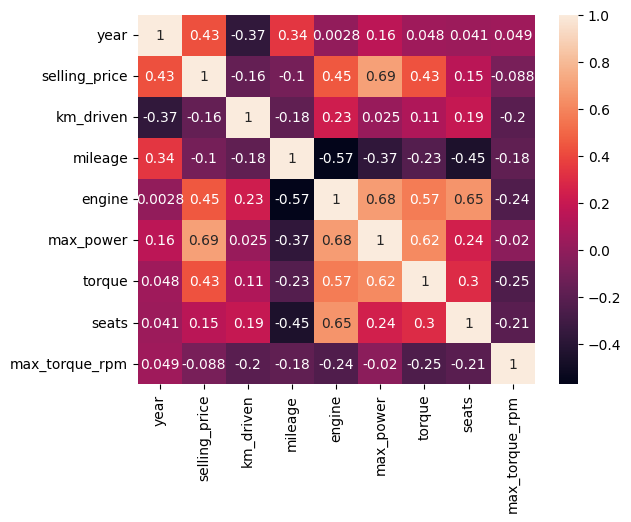

In [338]:
sns.heatmap(df_train.select_dtypes(['int', 'float']).corr(), annot=True)
plt.show()

- [ ] Ответьте на вопросы:
 - Какие 2 признака наименее скоррелированы между собой?
 - Между какими наблюдается довольно сильная положительная линейная зависимость?
 - Правильно ли, опираясь на данные, утверждать, что чем меньше год, тем, скорее всего, больше километров проехала машина к дате продажи?
 - Изучите типы корреляций в `DataFrame.corr()`. Какую вы использовали по умолчанию?

In [339]:
#решил помучиться и вытащить признаки из матрицы
corr_df = df_train.select_dtypes(['int', 'float']).corr()
mask = np.triu(np.ones(corr_df.shape, dtype=bool), k=1) #берем только значения лежащие выше главной диагонали
pairs = corr_df.where(mask).stack()#стакаю признаки, чтобы вытащить нужные признаки
feature1, feature2 = pairs.abs().idxmin()


strong_corr = pairs[pairs >= 0.6].sort_values(ascending=False)

print(f'Наименее скоррелированные признаки: {feature1}, {feature2}')
print('Признаки с высокой положительной корреляцией:')
display(strong_corr)
display(corr_df.loc['year', 'km_driven'])

Наименее скоррелированные признаки: year, engine
Признаки с высокой положительной корреляцией:


selling_price  max_power    0.692814
engine         max_power    0.681117
               seats        0.652172
max_power      torque       0.616197
dtype: float64

np.float64(-0.36896578600117047)

- Да, можно утверждать. Однако, стоит сказать, что корреляция отрицательная и связь есть, но это не правило.
- По умолчанию используется корреляция Пирсона, но есть и другие.

### **Задание 10 (0.35 балла)**

По умолчанию `DataFrame.corr` возвращает корреляцию Пирсона, говорящую о линейной взаимосвязи. Но зависимости существуют не только линейные! В этой задаче, попробуйте другие способы вычисления корреляций.

- [ ] Реализуйте корреляцию Спирмена/Кендалла (на выбор) без использования библиотек (можно пользоваться только `numpy`). Сравните результаты вычисления с библиотечной реализацией
- [ ] Сделайте выводы


Постройте матрицу корреляции [phik](https://pypi.org/project/phik/)
- [ ] Проинтерпретируйте результаты

In [340]:
def spearmen_correlation(x, y):

  def get_ranks(data):
    sorted = np.sort(data).tolist()
    ranks = []
    for val in data:
      first_idx = sorted.index(val)
      count = sorted.count(val)
      avg_rank = np.sum(range(first_idx+1, first_idx+count+1)) / count
      ranks.append(avg_rank)
    return np.asarray(ranks)

  rank_x = get_ranks(x)
  rank_y = get_ranks(y)

  centered_x = rank_x - np.mean(rank_x)
  centered_y = rank_y - np.mean(rank_y)

  num = np.sum(centered_x * centered_y)
  denominator = np.sqrt(
      np.sum(centered_x ** 2) * np.sum(centered_y ** 2)
  )
  return num / denominator if denominator != 0 else np.nan


spearmen_matrix = df_train.select_dtypes(['int', 'float']).corr(method='spearman')
display(spearmen_matrix)

assert np.allclose(spearmen_matrix.loc['year', 'km_driven'], spearmen_correlation(df_train["year"], df_train["km_driven"])) == True #проверил, что корреляции получаются одинаковые

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
year,1.000000,0.707123,-0.569659,0.346132,-0.038056,0.165798,0.102603,0.048291,0.076801
selling_price,0.707123,1.000000,-0.295665,0.026186,0.463577,0.612258,0.582414,0.317605,-0.126948
km_driven,-0.569659,-0.295665,1.000000,-0.198466,0.304504,0.040919,0.242934,0.195317,-0.321022
mileage,0.346132,0.026186,-0.198466,1.000000,-0.429871,-0.308824,-0.162381,-0.435458,-0.177191
engine,-0.038056,0.463577,0.304504,-0.429871,1.000000,0.713113,0.842430,0.527716,-0.372690
max_power,0.165798,0.612258,0.040919,-0.308824,0.713113,1.000000,0.779600,0.304857,-0.024798
torque,0.102603,0.582414,0.242934,-0.162381,0.842430,0.779600,1.000000,0.438233,-0.526370
seats,0.048291,0.317605,0.195317,-0.435458,0.527716,0.304857,0.438233,1.000000,-0.201905
max_torque_rpm,0.076801,-0.126948,-0.321022,-0.177191,-0.372690,-0.024798,-0.526370,-0.201905,1.000000


У меня получилось реализовать самописную корреляцию Спирменаи результат совпал с бибилиотечной версией

In [341]:
df_train.phik_matrix()

interval columns not set, guessing: ['year', 'selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'torque', 'seats', 'max_torque_rpm']


/usr/local/lib/python3.13/dist-packages/phik/data_quality.py:59: UserWarning: The number of unique values of variable name is large: 1924. Are you sure this is not an interval variable? Analysis for pairs of variables including name can be slow.
  warnings.warn(


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,max_torque_rpm
name,1.000000,0.948995,0.994871,0.000000,1.000000,0.799127,1.000000,0.830098,0.999690,1.000000,0.997906,1.000000,0.999985,0.999942
year,0.948995,1.000000,0.219841,0.081574,0.205834,0.232412,0.153714,0.418636,0.279253,0.213156,0.381639,0.096307,0.288178,0.270159
selling_price,0.994871,0.219841,1.000000,0.000000,0.157885,0.334505,0.463058,0.557641,0.649768,0.503682,0.872166,0.423431,0.196447,0.203871
km_driven,0.000000,0.081574,0.000000,1.000000,0.046285,0.000000,0.012824,0.087887,0.081625,0.210747,0.000000,0.000000,0.096223,0.049752
fuel,1.000000,0.205834,0.157885,0.046285,1.000000,0.050771,0.053721,0.030943,0.582304,0.644421,0.236006,0.085412,0.450714,0.564287
seller_type,0.799127,0.232412,0.334505,0.000000,0.050771,1.000000,0.127968,0.176612,0.064736,0.160346,0.331904,0.074575,0.032173,0.149330
transmission,1.000000,0.153714,0.463058,0.012824,0.053721,0.127968,1.000000,0.096990,0.331889,0.520161,0.511877,0.404678,0.045734,0.030797
owner,0.830098,0.418636,0.557641,0.087887,0.030943,0.176612,0.096990,1.000000,0.152406,0.186011,0.121438,0.039605,0.046741,0.112596
mileage,0.999690,0.279253,0.649768,0.081625,0.582304,0.064736,0.331889,0.152406,1.000000,0.588155,0.687235,0.204598,0.679979,0.312237
engine,1.000000,0.213156,0.503682,0.210747,0.644421,0.160346,0.520161,0.186011,0.588155,1.000000,0.720780,0.466097,0.603400,0.640941


Наиболее сильно с ценой связаны `name` 0,995 и `max_power` 0,872. Также заметна связь с `mileage` 0,650, `owner` 0,558 и `engine` 0,504. Между признаками выделяются пары `torque - max_torque_rpm` 0,943 и `engine — max_power` 0,721. PhiK отражает силу зависимости, включая нелинейную, но не показывает её направление.

### **Задание 11 (0.1 балла)**

Если вам кажется, что мы не попросили вас нарисовать какие-то очень важные зависимости, нарисуйте их **и поясните.**

- [ ] Постройте хотя бы одну дополнительную визуализацию и объясните, что она показывает и почему это важно.

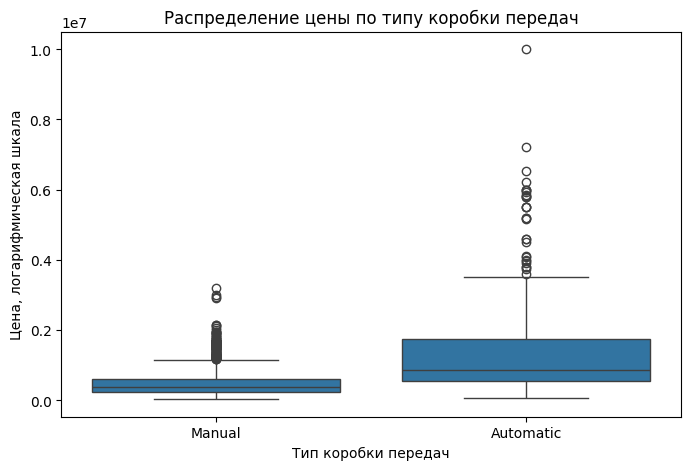

In [342]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_train,
    x="transmission",
    y="selling_price"
)

# plt.yscale("log")
plt.xlabel("Тип коробки передач")
plt.ylabel("Цена, логарифмическая шкала")
plt.title("Распределение цены по типу коробки передач")
plt.show()

Boxplot позволяет сравнить медианные цены и разброс цен автомобилей с разными типами коробки передач.Поскольку матрица PhiK показала связь между transmission и selling_price (0,463), а график позволяет подробнее изучить различия между группами.

# **Часть 2 (1.4 балла) | Модель только на вещественных признаках**

В этой части вам предстоит обучить модель только на вещественных признаках. Почему только на них?

Чем больше признаковое пространство — тем сложнее модель. А чем модель проще — тем лучше для скорости работы и интерпретации признаков.

За задания этой части вы можете набрать 1.4 балла.

### **Задание 12 (0.05 балла)**

Сделайте тренировочный и тестовый наборы. Они уже даны, достаточно просто отделить целевой признак. Перед разбиением создайте копию датафрейма, который будет хранить только вещественные признаки и используйте его (то есть категориальные столбцы (все, кроме seats) необходимо удалить).

В переменные y_train и y_test запишите значения целевых переменных. Используйте уже имеющиеся данные train и test. Если считаете уместным применить какую-то более хитрую технику разбиения — примените, но опишите, зачем.

In [343]:
y_train = df_train['selling_price']
X_train = df_train.select_dtypes(['int', 'float']).drop('selling_price', axis=1)

In [344]:
# опишите выбранные вещественные признаки

In [345]:
y_test = df_test['selling_price']
X_test = df_test.select_dtypes(['int', 'float']).drop('selling_price', axis=1)

### **Задание 13 (0.2 балла)**

Построим нашу первую модель!
- [ ] Обучите классическую линейную регрессию с дефолтными параметрами. Посчитайте $R^2$ и $MSE$ для трейна и для теста.
- [ ] Сделайте выводы по значениям метрик качества.

**Примечание:**

Здесь и далее $R^2$ и $MSE$ для трейна и для теста выводите везде, где требуется обучать модели, даже если в явном виде этого не просят. Иначе непонятно, как понять, насколько успешны наши эксперименты.

In [346]:
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_test = lr.predict(X_test)
pred_train = lr.predict(X_train)
print(f'R2 on train: {r2_score(y_train, pred_train)}')
print(f'MSE on train: {MSE(y_train, pred_train)}')
print(f'R2 on test: {r2_score(y_test, pred_test)}')
print(f'MSE on test: {MSE(y_test, pred_test)}')

R2 on train: 0.6010685156695217
MSE on train: 114349057787.13358
R2 on test: 0.6004562418103663
MSE on test: 229669161434.50305


- Качество модели на трейне и на тесте не сильно отличается (0.601 и 0.6004). Модель объясняет примерно 60% дисперсии в данных. Так как метрика не сильно отличается, то скорее всего у нас нет переобучения.
- MSE на тесте в два раза больше чем на трейне, это можно объяснить более высоким стандартным отклонением на тесте.

### **Задание 14 (0.25 балла)**

**Шаг 1 (0.15 балла)**
- [ ] Реализуйте $R^2$ руками. Приведите формулу $R^2$ и объясните каждую компоненту метрики

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}
{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

- n — количество наблюдений.
- y_i — фактическая цена автомобиля.
- y^ — предсказанная моделью цена.
- "y-" — средняя фактическая цена в выборке.
- Числитель — сумма квадратов ошибок модели.
- Знаменатель — сумма квадратов отклонений цен от среднего.

In [347]:
def r_2_score(y_true, y_pred):
  y_mean = np.mean(y_true)
  numerator = np.sum((y_true - y_pred) ** 2)
  denominator = np.sum((y_true - y_mean) ** 2)
  return 1 - (numerator / denominator)

**Шаг 2 (0.1 балла)**

- [ ] Реализуйте [$\text{adjusted}-R^2$](https://en.wikipedia.org/wiki/Coefficient_of_determination).
- [ ] Объясните, когда применяется $\text{adjusted}-R^2$?

In [348]:
def adjusted_r2_score(y_true, y_pred, X):
  r2 = r_2_score(y_true, y_pred)
  n = X.shape[0]
  p = X.shape[1]
  return 1 - (1 - r2) * (n - 1) / (n - p - 1)

`adjusted−𝑅2` используется для сравнения моделей с разным количеством признаков на одной и той же выборке. При обычном r2 у нас качество не снижается при добавлении новых признаков, даже если они бесполезные, а adjusted-r2 может снизиться из-за добавления таких признаков.

### **Задание 15 (0.05 балла)**

Всегда есть место совершенству. Поэтому давайте попробуем улучшить модель при помощи стандартизации признаков.

- [ ] Стандартизируйте значения в тренировочных и тестовых данных. Стандартизатор **обучайте только на `train`**.

In [349]:
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

lr = LinearRegression()
lr.fit(X_train, y_train)
pred_test = lr.predict(X_test)
pred_train = lr.predict(X_train)
print(f'R2 on train: {r2_score(y_train, pred_train)}')
print(f'MSE on train: {MSE(y_train, pred_train)}')
print(f'R2 on test: {r2_score(y_test, pred_test)}')
print(f'MSE on test: {MSE(y_test, pred_test)}')

R2 on train: 0.601068515669521
MSE on train: 114349057787.13377
R2 on test: 0.6004562418103654
MSE on test: 229669161434.50357


### **Задание 16 (0.1 балла)**

Хотя стандартизация не помогла сильно прибавить в качестве, она открыла возможность интерпретировать важность признаков в модели. Правило интерпретации такое:

Чем больше коэффициент $\beta_i$ по модулю, тем важнее признак.

**Ответьте на вопрос:**

- [ ] Какой признак оказался наиболее информативным в предсказании цены?

In [350]:
pd.DataFrame([np.abs(lr.coef_)], columns=X_train.columns)

,year,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
0,165430.152796,48943.784558,8129.243931,22925.420038,330860.359594,4602.595882,30147.112236,59508.031622


Самый важный признак это `max_power`

### **Задание 17 (0.2 балла)**

Попробуем улучшить нашу модель с помощью применения регуляризации. Для этого воспользуемся `Lasso` регрессией.  Кроме того, попробуйте использовать её теоретическое свойство отбора признаков, за счет зануления незначимых коэффициентов.

**Задание:**

- [ ] Обучите Lasso регрессию на тренировочном наборе данных со стандартизованными признаками. Оцените её качество
- [ ] Проверьте, занулила ли L1-регуляризация с параметрами по умолчанию какие-нибудь веса? Предположите почему.

In [351]:
lasso = Lasso()
lasso.fit(X_train, y_train)
pred_test = lasso.predict(X_test)
pred_train = lasso.predict(X_train)

print(f'R2 on train: {r2_score(y_train, pred_train)}')
print(f'MSE on train: {MSE(y_train, pred_train)}')
print(f'R2 on test: {r2_score(y_test, pred_test)}')
print(f'MSE on test: {MSE(y_test, pred_test)}')

R2 on train: 0.6010685156219819
MSE on train: 114349057800.76027
R2 on test: 0.6004549580584178
MSE on test: 229669899371.7814


In [352]:
pd.DataFrame([np.abs(lasso.coef_)], columns=X_train.columns)

,year,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
0,165427.955403,48942.841995,8125.959832,22923.417822,330861.729341,4601.962878,30143.134279,59505.937456


- Lasso не занулила никакие веса. Скорее всего это связано с слабой регуляризацией, по умолчанию alpha=1, а целевая переменная имеет большой масштаб и не стандартизирована.

### **Задание 18. Финальный рывок (0.3 балла)**

До этого мы с вами использовали `train` для обучения и `test` для прогнозирования. Но у нас есть ещё одна задача — подобрать оптимальные параметры модели. Для этого используем кросс-валидацию, описанную на семинарах.

Кроме того, выжмем максимум из модификаций регрессии. Построим `ElasticNet`. И сделаем всё по порядку.

**Ваша задача 1:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для Lasso-регрессии. Вам пригодится класс [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Что значит каждый параметр `param_grid`, который вы заполняли для `GridSearch`? Опишите каждый
 - Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?

In [353]:
%%time
param_grid = {
    'alpha': np.logspace(-2, 6, 50)
}

cv = GridSearchCV(Lasso(), param_grid, cv=10, scoring='r2')
cv.fit(X_train, y_train)
print(cv.best_params_)
np.sum(cv.best_estimator_.coef_ == 0)

{'alpha': np.float64(23299.51810515367)}
CPU times: user 2.02 s, sys: 3.16 ms, total: 2.02 s
Wall time: 2 s


np.int64(4)

In [354]:
lasso_no_cat = Lasso(alpha = 23299.52)
lasso_no_cat.fit(X_train, y_train)
pred_test_lasso_no_cat = lasso_no_cat.predict(X_test)
pred_train_lasso_no_cat = lasso_no_cat.predict(X_train)

- обучение заняло 4.84 секунды.
- Lasso() - это сама модель
- param_grid - словарь с параметрами для перебора
- cv - количество фолдов, на которые будут разбиваться данные
- scoring - метрика, по которой будет выбираться лучшая модель
- Лучшим коэффициентом оказалось значение 23299.51
- Занулилось 4 признака

**Ваша задача 2:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) регрессии.
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?

In [355]:
%%time
param_grid = {
    'alpha': np.logspace(-2, 7, 100),
    'l1_ratio': [0.1, 0.5, 0.9, 0.99, 1.0]
}

cv = GridSearchCV(ElasticNet(), param_grid, cv=10, scoring='r2')
cv.fit(X_train, y_train)
print(cv.best_params_)
print(cv.best_score_)
print(np.sum(cv.best_estimator_.coef_ == 0))

{'alpha': np.float64(23101.297000831626), 'l1_ratio': 1.0}
0.5832256814244399
4
CPU times: user 18.9 s, sys: 13.4 ms, total: 18.9 s
Wall time: 19 s


- Я увеличил количество перебираемых значений в итоге получилось найти лучшие гиперпараметры за 19.3 секунды
- Лучшие гиперпараметры: 'alpha': np.float64(23101.297000831626), 'l1_ratio': 1.0

In [356]:
elastic_no_cat = ElasticNet(alpha = 23101.3, l1_ratio=1.0)
elastic_no_cat.fit(X_train, y_train)
pred_test_elastic_no_cat = elastic_no_cat.predict(X_test)
pred_train_elastic_no_cat = elastic_no_cat.predict(X_train)

### **Задание 19 (0.25 балла)**

Итак, вы обучили все варианты регуляризаций, доступные в sklearn, но не все, что мы обсудили на занятии! Следующее задание — о забытой $L0$-регуляризации.

Задача линейной регрессии с $L0$-регуляризацией:

$$\min_{w}\; \frac{1}{n}\|y - Xw\|_2^2 + \lambda \|w\|_0, \qquad \|w\|_0 = \#\{j : w_j \neq 0\}.$$

Штраф $\|w\|_0$ разрывный и невыпуклый, поэтому градиентным спуском «в лоб» задачу не решить. **Выберите один** из способов (или предложите свой и обоснуйте его):

1. **Полный перебор подмножеств (best subset selection).** Для каждого подмножества признаков $S$ обучите МНК только на признаках из $S$ (веса $\hat w_S$) и выберите
$$S^* = \arg\min_{S}\; \frac{1}{n}\|y - X_S \hat w_S\|_2^2 + \lambda |S|.$$
Перебор $2^d$ подмножеств реален при небольшом числе признаков $d$ (у нас вещественных признаков меньше десяти).

2. **Жадный отбор (forward / backward stepwise).** Начните с пустого (полного) набора признаков и на каждом шаге добавляйте (удаляйте) тот признак, который сильнее всего уменьшает $\frac{1}{n}\|y - X_S \hat w_S\|_2^2 + \lambda |S|$. Остановитесь, когда функционал перестанет уменьшаться.

3. **Iterative Hard Thresholding (проксимальный градиентный спуск).** Сделайте шаг градиентного спуска по MSE с шагом $\eta$, затем занулите малые веса:
$$z = w^{(t)} - \eta\, \nabla_w \tfrac{1}{n}\|y - Xw^{(t)}\|_2^2, \qquad w^{(t+1)}_j = z_j \cdot \mathbb{1}\left[|z_j| > \sqrt{2\eta\lambda}\right].$$

4. **Стохастические «ворота» с hard concrete распределением** ([Louizos et al., 2018](https://arxiv.org/abs/1712.01312)). Веса параметризуются как $w = \tilde w \odot z$, где $z_j \in [0, 1]$:
$$u_j \sim U(0,1),\quad s_j = \sigma\!\left(\frac{\log u_j - \log(1-u_j) + \log\alpha_j}{\beta}\right),\quad z_j = \min\big(1, \max(0,\, s_j(\zeta-\gamma)+\gamma)\big),$$
а недифференцируемый $\|w\|_0$ заменяется на его матожидание $\sum_j P(z_j \neq 0)$:
$$\min_{\tilde w,\, \log\alpha}\; \mathbb{E}_u\!\left[\frac{1}{n}\|y - X(\tilde w \odot z)\|_2^2\right] + \lambda\sum_{j}\sigma\!\left(\log\alpha_j - \beta\log\frac{-\gamma}{\zeta}\right).$$
Типичные значения: $\beta = \frac{2}{3},\ \gamma = -0.1,\ \zeta = 1.1$. Оптимизируйте градиентным спуском (например, в PyTorch). На инференсе используйте детерминированные ворота $z_j = \min\big(1, \max(0,\, \sigma(\log\alpha_j)(\zeta-\gamma)+\gamma)\big)$.

Для способов 3 и 4 признаки должны быть стандартизованы.

**Ваша задача:**
- [ ] Реализуйте модель с $L0$-регуляризацией одним из способов выше.
- [ ] Обучите модель при нескольких значениях $\lambda$ и проанализируйте, как меняются число ненулевых весов и качество ($R^2$ и $MSE$ на трейне и тесте).

**Важно:**

Несмотря на то что L0 не реализована в стандартных пакетах, концепция данной регуляризации не является мертвой. Она встречается в статьях и экспериментах.

In [357]:
# your code here

# **Часть 3 (0.5 балла) | Добавляем категориальные фичи**

Попробуем для улучшения модели дать ей больше признаков. Добавим категориальные фичи.

За эту часть можно набрать 0.5 балла.

### **Задание 20 (0.1 балла)**

Проанализируйте столбец `name`. Очевидно, что эта переменная является категориальной, однако категорий в ней много.

- [ ] Создайте `X_train_cat` и `X_test_cat` — копии `df_train` и `df_test` без целевой переменной (со всеми признаками, включая категориальные)
- [ ] Предобработайте столбец `name`, чтобы избежать его удаления

In [358]:
X_train_cat = df_train.drop('selling_price', axis=1)
X_test_cat = df_test.drop('selling_price', axis=1)
X_train_cat['brand'] = X_train_cat['name'].apply(lambda x: x.split(' ')[0])
X_test_cat['brand'] = X_test_cat['name'].apply(lambda x: x.split(' ')[0])
X_train_cat['model'] = X_train_cat['name'].apply(lambda x: x.split(' ')[1])
X_test_cat['model'] = X_test_cat['name'].apply(lambda x: x.split(' ')[1])
X_train_cat.drop('name', axis=1, inplace=True)
X_test_cat.drop('name', axis=1, inplace=True)
X_train_cat

,year,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,max_torque_rpm,brand,model
0,2014,145500,Diesel,Individual,Manual,First Owner,23.40,1248,74.00,190.000000,5,2000.0,Maruti,Swift
1,2014,120000,Diesel,Individual,Manual,Second Owner,21.14,1498,103.52,250.000000,5,2500.0,Skoda,Rapid
2,2010,127000,Diesel,Individual,Manual,First Owner,23.00,1396,90.00,219.668960,5,2750.0,Hyundai,i20
3,2007,120000,Petrol,Individual,Manual,First Owner,16.10,1298,88.20,112.776475,5,4500.0,Maruti,Swift
4,2017,45000,Petrol,Individual,Manual,First Owner,20.14,1197,81.86,113.750000,5,4000.0,Hyundai,Xcent
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5835,2008,191000,Petrol,Individual,Manual,First Owner,17.92,1086,62.10,96.100000,5,3000.0,Hyundai,Santro
5836,2013,50000,Petrol,Individual,Manual,Second Owner,18.90,998,67.10,90.000000,5,3500.0,Maruti,Wagon
5837,2013,110000,Petrol,Individual,Manual,First Owner,18.50,1197,82.85,113.700000,5,4000.0,Hyundai,i20
5838,2007,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.80,1493,110.00,235.359600,5,2750.0,Hyundai,Verna


In [359]:
# 14 столбцов после разбиения torque, минус selling_price; name предобработан в один столбец.
# Если из name получилось несколько столбцов — скорректируйте ожидаемую размерность.
assert X_train_cat.shape == (5840, 14)

In [360]:
X_train_cat.describe(include='object')

,fuel,seller_type,transmission,owner,brand,model
count,5840,5840,5840,5840,5840,5840
unique,4,3,2,5,30,202
top,Diesel,Individual,Manual,First Owner,Maruti,Swift
freq,3177,5223,5336,3603,1804,558


### **Задание 21 (0.1 балла)**

- [ ] Закодируйте категориальные фичи и ``seats`` методом OneHot-кодирования.

In [361]:
X_train_cat

,year,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,max_torque_rpm,brand,model
0,2014,145500,Diesel,Individual,Manual,First Owner,23.40,1248,74.00,190.000000,5,2000.0,Maruti,Swift
1,2014,120000,Diesel,Individual,Manual,Second Owner,21.14,1498,103.52,250.000000,5,2500.0,Skoda,Rapid
2,2010,127000,Diesel,Individual,Manual,First Owner,23.00,1396,90.00,219.668960,5,2750.0,Hyundai,i20
3,2007,120000,Petrol,Individual,Manual,First Owner,16.10,1298,88.20,112.776475,5,4500.0,Maruti,Swift
4,2017,45000,Petrol,Individual,Manual,First Owner,20.14,1197,81.86,113.750000,5,4000.0,Hyundai,Xcent
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5835,2008,191000,Petrol,Individual,Manual,First Owner,17.92,1086,62.10,96.100000,5,3000.0,Hyundai,Santro
5836,2013,50000,Petrol,Individual,Manual,Second Owner,18.90,998,67.10,90.000000,5,3500.0,Maruti,Wagon
5837,2013,110000,Petrol,Individual,Manual,First Owner,18.50,1197,82.85,113.700000,5,4000.0,Hyundai,i20
5838,2007,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.80,1493,110.00,235.359600,5,2750.0,Hyundai,Verna


In [362]:
cat_cols = X_train_cat.select_dtypes(include="object").columns.tolist()

if "seats" not in cat_cols:
    cat_cols.append("seats")

encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

encoder.fit(X_train_cat[cat_cols])


def encode_categories(X):
    encoded = pd.DataFrame(
        encoder.transform(X[cat_cols]),
        columns=encoder.get_feature_names_out(cat_cols),
        index=X.index
    )

    return pd.concat([X.drop(columns=cat_cols), encoded], axis=1)


X_train_cat = encode_categories(X_train_cat)
X_test_cat = encode_categories(X_test_cat)
X_train_cat

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,year,km_driven,mileage,engine,max_power,torque,max_torque_rpm,fuel_Diesel,fuel_LPG,fuel_Petrol,...,model_i10,model_i20,seats_4,seats_5,seats_6,seats_7,seats_8,seats_9,seats_10,seats_14
0,2014,145500,23.40,1248,74.00,190.000000,2000.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2014,120000,21.14,1498,103.52,250.000000,2500.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2010,127000,23.00,1396,90.00,219.668960,2750.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2007,120000,16.10,1298,88.20,112.776475,4500.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2017,45000,20.14,1197,81.86,113.750000,4000.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5835,2008,191000,17.92,1086,62.10,96.100000,3000.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5836,2013,50000,18.90,998,67.10,90.000000,3500.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5837,2013,110000,18.50,1197,82.85,113.700000,4000.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5838,2007,119000,16.80,1493,110.00,235.359600,2750.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


### **Задание 22 (0.2 балла)**

OHE — базовый алгоритм преобразования категориальных признаков, но и с ним нужно быть аккуратными.

**Ответьте на вопросы:**


* Как корректно работать с OHE преобразованием?
* Почему мы удаляем один столбец?
* Пусть из категориального признака с $n$ категориями мы получили $n-1$ столбец, из которых $k < n-1$ оказались неважными по весам модели. Корректно ли их удалить?

- обучать кодировщик только на `train` и применять к тесту, неизвестные категории обрабатывать с помощью параметра hanndle_unknown
- Мы удаляем один столбец, чтобы убрать линейную связь между получившимися признаками
- Нет, они отражают отличие объектов от базовой категории, при удалении мы все схлопнем до одной категории

### **Задание 23 (0.1 балла)**
Повторим то, что делали на прошлом шаге для моделей на вещественных признаках, однако теперь с моделью `Ridge`.


**Ваша задача:**
- [ ] Переберите параметр регуляризации `alpha` для гребневой (ridge) регрессии с помощью класса `GridSearchCV`. В качестве параметров при объявлении GridSearchCV кроме модели укажите метрику качества $R^2$. Кроссвалидируйтесь по 10-ти фолдам.
- [ ] Ответьте на вопрос: Удалось ли улучшить качество прогнозов?

In [363]:
%%time
param_grid = {
    'alpha': np.logspace(-2, 6, 50)
}

cv = GridSearchCV(Ridge(), param_grid, cv=10, scoring='r2')
cv.fit(X_train_cat, y_train)
print(cv.best_params_)
print(cv.best_score_)
np.sum(cv.best_estimator_.coef_ == 0)

{'alpha': np.float64(0.42919342601287763)}
0.7842310669554375
CPU times: user 1min 8s, sys: 84.1 ms, total: 1min 8s
Wall time: 37.5 s


np.int64(0)

Качество и вправду получилось улучшить, оно поднялось до `0.78`, а раньше было около `0.6`.

In [364]:
ridge_cat_no_fe = Ridge(alpha = 0.3)
ridge_cat_no_fe.fit(X_train_cat, y_train)
pred_test_ridge_cat_no_fe = ridge_cat_no_fe.predict(X_test_cat)
pred_train_ridge_cat_no_fe = ridge_cat_no_fe.predict(X_train_cat)

# **Часть 4 (0.4 балла) | Feature Engineering**

### **Задание 24 (0.4 балла)**

В этой части домашнего задания вам предлагается проявить свою креативность для улучшения прогноза модели. Любые другие модели, кроме различных форм линейной (или полиномиальной) регрессии, использовать запрещается. А значит, придется работать с признаками

**Что можно попробовать сделать?** (каждый пункт — до 0.2 балла, но не больше 0.4 балла в сумме)

1.   *Сгенерировать новые признаки на основе уже существующих:*
    * посчитать произведения // частные признаков (кажется, что посчитать число "лошадей" на литр объема может быть полезно);
    * имеет смысл обратить внимание на визуализации в части с EDA (к примеру, зависимость цены от года выглядит квадратичной, а не линейной; значит, квадрат года нам, скорее всего, принесет больше пользы)

2.   *Добыть новые признаки:*
    * из названия автомобиля можно извлечь больше информации (например, спарсить инфу о классе автомобиля или каких-то специфических опциях)
    * можно добавить пороговые признаки вроде "владелец третий или больше" и объединить признаки в некоторые осмысленные правила, например "первый или второй владелец и продавец официальный дилер" (подбирать пороги удобно по диаграммам рассеяния)

3.   *Поработать с уже имеющимися:*
    * далеко не факт, что заполнить пропуск медианой было лучшей идеей (как минимум, можно добавить dummy-столбец для модели, сигнализирующий, что раньше на месте медианы был пропуск -- там где он был, конечно); попробуйте другие способы филлинга;
    * мы не анализировали, есть ли в данных выбросы => никак выбросы не обрабатывали; наиболее простым и, тем не менее, довольно полезным вариантом нахождения выбросов могут послужить boxplot'ы для каждого столбца; что делать с выбросами думайте сами :) -- вариантов довольно много
    * мы толком не смотрели на таргет сам по себе; в нем тоже могут быть неожиданности -- стоит хотя бы проверить
    * можно заметить, что некоторые признаки распределены совсем не нормально; возможно их стоит отлогарифмировать

И так далее...

Feel Free to Try!

In [365]:
missing_cols = [
    "mileage", "engine", "max_power",
    "torque", "max_torque_rpm", "seats"
]

df_train_new = df_train.copy()
df_test_new = df_test.copy()

for df in [df_train_new, df_test_new]:
    for col in missing_cols:
        df[f"{col}_missing"] = df[col].isna().astype(int)

    year_centered = df["year"] - 2010
    engine_liters = df["engine"].where(df["engine"] > 0) / 1000
    df["power_per_liter"] = df["max_power"] / engine_liters
    df["year_squared"] = (year_centered) ** 2
    df["log_km_driven"] = np.log1p(df["km_driven"])
    df["log_torque"] = np.log1p(df["torque"])
    df["power_squared"] = df["max_power"] ** 2

    df["power_x_year"] = df["max_power"] * year_centered
    df["log_km_x_year"] = np.log1p(df["km_driven"]) * year_centered


numeric_cols = df_train_new.select_dtypes(include="number").columns.drop(
    "selling_price"
)
medians = df_train_new[numeric_cols].median()

df_train_new[numeric_cols] = df_train_new[numeric_cols].fillna(medians)
df_test_new[numeric_cols] = df_test_new[numeric_cols].fillna(medians)

In [366]:
X_train_cat_new = df_train_new.drop('selling_price', axis=1)
X_test_cat_new = df_test_new.drop('selling_price', axis=1)
X_train_cat_new['brand'] = X_train_cat_new['name'].apply(lambda x: x.split(' ')[0])
X_test_cat_new['brand'] = X_test_cat_new['name'].apply(lambda x: x.split(' ')[0])
X_train_cat_new['model'] = X_train_cat_new['name'].apply(lambda x: x.split(' ')[1])
X_test_cat_new['model'] = X_test_cat_new['name'].apply(lambda x: x.split(' ')[1])
X_train_cat_new.drop('name', axis=1, inplace=True)
X_test_cat_new.drop('name', axis=1, inplace=True)


In [367]:
cat_cols = X_train_cat_new.select_dtypes(include="object").columns.tolist()

if "seats" not in cat_cols:
    cat_cols.append("seats")

encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

encoder.fit(X_train_cat_new[cat_cols])


def encode_categories(X):
    encoded = pd.DataFrame(
        encoder.transform(X[cat_cols]),
        columns=encoder.get_feature_names_out(cat_cols),
        index=X.index
    )

    return pd.concat([X.drop(columns=cat_cols), encoded], axis=1)


X_train_cat_new = encode_categories(X_train_cat_new)
X_test_cat_new = encode_categories(X_test_cat_new)
X_train_cat_new

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,year,km_driven,mileage,engine,max_power,torque,max_torque_rpm,mileage_missing,engine_missing,max_power_missing,...,model_i10,model_i20,seats_4,seats_5,seats_6,seats_7,seats_8,seats_9,seats_10,seats_14
0,2014,145500,23.40,1248,74.00,190.000000,2000.0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2014,120000,21.14,1498,103.52,250.000000,2500.0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2010,127000,23.00,1396,90.00,219.668960,2750.0,0,0,0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2007,120000,16.10,1298,88.20,112.776475,4500.0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2017,45000,20.14,1197,81.86,113.750000,4000.0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5835,2008,191000,17.92,1086,62.10,96.100000,3000.0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5836,2013,50000,18.90,998,67.10,90.000000,3500.0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5837,2013,110000,18.50,1197,82.85,113.700000,4000.0,0,0,0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5838,2007,119000,16.80,1493,110.00,235.359600,2750.0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [368]:
%%time
param_grid = {
    'alpha': np.logspace(-2, 6, 50)
}

cv = GridSearchCV(Ridge(), param_grid, cv=10, scoring='r2')
cv.fit(X_train_cat_new, y_train)
print(cv.best_params_)
print(cv.best_score_)
np.sum(cv.best_estimator_.coef_ == 0)

{'alpha': np.float64(0.9102981779915218)}
0.8702164641137948
CPU times: user 1min 14s, sys: 91.1 ms, total: 1min 14s
Wall time: 40.1 s


np.int64(6)

С помощью новых признаков получилось увеличить качество модели до 0.86, что несомненно лучше предыдущих моделей, которые были обучены на прежнем признаковом пространстве.

In [369]:
ridge_cat_fe = Ridge(alpha = 0.9)
ridge_cat_fe.fit(X_train_cat_new, y_train)
pred_test_ridge_cat_fe = ridge_cat_fe.predict(X_test_cat_new)
pred_train_ridge_cat_fe = ridge_cat_fe.predict(X_train_cat_new)

# **Часть 5 | Бизнесовая (0.4 балла)**

### **Задание 25 (0.2 балла)**

В мире бизнеса очень важно давать оценку качества модели понятную бизнесу, поэтому иногда заказчики приходят с кастомными метриками. Попробуем сделать такую для нашей задачи.

**Описание метрики:**

Среди всех предсказанных цен на авто нужно посчитать долю прогнозов, отличающихся от реальных цен на эти авто не более чем на 10% (в одну или другую сторону). Отклонение считается относительно **реальной** цены $y_i$:

$$\text{business\_metrics}(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\frac{|\hat y_i - y_i|}{y_i} \le 0.1\right]$$

**Ваша задача:**

- [ ] Реализуйте метрику `business_metrics`
- [ ] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [370]:
models = {
    'Lasso_no_cat': pred_test_lasso_no_cat,
    'Elastic_no_cat': pred_test_elastic_no_cat,
    'Ridge_cat_no_fe': pred_test_ridge_cat_no_fe,
    'Ridge_cat_fe': pred_test_ridge_cat_fe
}

In [379]:
def business_metrics(y_true, y_pred):
    return np.mean(np.abs(y_pred - y_true) / y_true <= 0.1)

for model in models:
    print(f'Для модели {model}, бизнес метрика равна {business_metrics(y_test, models[model])}')
    print(f'Для модели {model}, r2 равна {r2_score(y_test, models[model])}')

Для модели Lasso_no_cat, бизнес метрика равна 0.251
Для модели Lasso_no_cat, r2 равна 0.5721099125245783
Для модели Elastic_no_cat, бизнес метрика равна 0.252
Для модели Elastic_no_cat, r2 равна 0.5723443627835307
Для модели Ridge_cat_no_fe, бизнес метрика равна 0.361
Для модели Ridge_cat_no_fe, r2 равна 0.9248960581089
Для модели Ridge_cat_fe, бизнес метрика равна 0.379
Для модели Ridge_cat_fe, r2 равна 0.9453155975138656


Как видим лучшее значение метрики получилось у последне модели с категориальными и новыми категориальными признаками.

### **Задание 26 (0.2 балла)**

Но у бизнеса не всегда есть идеи и иногда задача на выбор метрики делегируется вам.

**Задание:**

- [ ] Придумайте и реализуйте другую кастомную метрику с учетом того, что модель не должна сильно ошибаться в прогнозе, но недопрогноз для модели, согласно мнению бизнеса, хуже, чем перепрогноз.
- [ ] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

Можно взять асимметричную квадратичную относительную ошибку:
- Ошибку считаем относительно реальной цены.
- Возводим её в квадрат, чтобы сильнее штрафовать большие промахи.
- За недопрогноз назначаем двойной штраф. Коэффициент 2 — выбираем сами.
Чем меньше метрика, тем лучше

In [372]:
def your_business_metrics(y_true, y_pred, under_weight=2):
    relative_error = (y_pred - y_true) / y_true

    weights = np.where(relative_error < 0, under_weight, 1)

    return np.mean(weights * relative_error ** 2)

def business_metrics(y_true, y_pred):
    return np.mean(np.abs(y_pred - y_true) / y_true <= 0.1)

for model in models:
    print(f'Для модели {model}, бизнес метрика равна {your_business_metrics(y_test, models[model])}')

Для модели Lasso_no_cat, бизнес метрика равна 3.049699762676004
Для модели Elastic_no_cat, бизнес метрика равна 3.0559815310233347
Для модели Ridge_cat_no_fe, бизнес метрика равна 0.7076070738458743
Для модели Ridge_cat_fe, бизнес метрика равна 0.32283808537836384


И опять последняя модель самая лучшая

# **Часть 6 | Оформление репозитория (2 балла)**

Домашнее задание оформите как репозиторий на GitHub.

---

### Обязательные файлы:

1. **`.ipynb`-ноутбук** со всеми экспериментами (0.5 балла):

   * полный EDA,
   * все шаги препроцессинга,
   * обучение и сравнение моделей,
   * сохранённые output’ы;
   * ноутбук запускается сверху вниз без ошибок.

2. **`.pickle`-файл** (0.5 балла), содержащий:

   * обученную модель (или пайплайн `scaler + model`);
   * параметры скейлинга;
   * любые числовые объекты, необходимые для инференса внутри Streamlit-приложения.

   Файл должен загружаться и делать предсказание на новых объектах.

3. **`.md`-файл с выводами** о проделанной работе (1 балл):

   * что было сделано (краткое описание каждого этапа), какие результаты были получены (метрики + интерпретация), что дало наибольший прирост качества (0.75 балла);
   * что сделать не удалось и почему — это нормально и даже полезно (0.25 балла).


### **За что могут быть сняты баллы:**

* отсутствие `.pickle` с моделью / пайплайном;
* слабая или неполная аналитика в `.md`-файле;
* беспорядок в ноутбуке или неясная логика вычислений.

# **<font color="green">Часть 7 | Создание интерактивного приложения на Streamlit (3 балла)</font>**

Вам необходимо создать интерактивное приложение на Streamlit (например, `app.py`), которое запускается командой

```bash
streamlit run app.py
```

и опубликовать его в [Streamlit Community Cloud](https://streamlit.io/cloud). Приложение должно:

- показывать основные информативные графики/гистограммы в рамках EDA (0.75 балла);
- на вход запрашивать csv-файл с признаками объектов или запрашивать признаки объекта в окошках для ввода, и применять на поступивших объектах модель из `.pickle`-файла (1 балл);
- визуализировать веса (коэффициенты) обученной модели (0.75 балла).

**Оценка сервиса (0.5 балла).** Дополните `.md`-файл из Части 6 разделом об оценке приложения:

* насколько приложение удобно в использовании;
* что получилось визуализировать хорошо, а что — менее удачно;
* какие ограничения или проблемы вы заметили;
* какие улучшения планируете в следующей итерации.

**Что нужно сдать:** код приложения в репозитории из Части 6 и ссылку на приложение в Streamlit Community Cloud.

**За что могут быть сняты баллы:** приложение не запускается командой выше или ссылка на него не открывается.

In [374]:
artifact = {
    "model": ridge_cat_fe,
    "encoder": encoder,
    "medians": medians,
    "numeric_columns": numeric_cols.tolist(),
    "categorical_columns": cat_cols.copy(),
    "feature_columns": X_train_cat_new.columns.tolist(),
    "missing_columns": missing_cols.copy(),
    "year_center": 2010,
    "sklearn_version": sklearn.__version__,
}

with open("ridge_cat_fe.pickle", "wb") as file:
    pickle.dump(artifact, file, protocol=pickle.HIGHEST_PROTOCOL)

print("Модель сохранена в ridge_cat_fe.pickle")
print("Версия scikit-learn:", sklearn.__version__)

Модель сохранена в ridge_cat_fe.pickle
Версия scikit-learn: 1.6.1


In [378]:
with open("ridge_cat_fe.pickle", "rb") as file:
    loaded = pickle.load(file)

pred_check = loaded["model"].predict(X_test_cat_new[loaded["feature_columns"]])

assert np.allclose(pred_check, pred_test_ridge_cat_fe)
print("Проверка пройдена: прогнозы совпадают")

Проверка пройдена: прогнозы совпадают
